# **1. Transformer가 등장하기까지**

RNN의 순차 처리 > Seq2Seq > 긴 문장의 정보 병목 > Attention > Transformer

# **2. 시퀀스투시퀀스**

시퀀스투시퀀스(Sequence-to-Sequence, Seq2Seq) 모델은 입력 시퀀스를 받아 출력 시퀀스를 생성하는 신경망 아키텍처로, 주로 자연어 처리 분야에서 번역, 요약, 질의응답 등에 활용된다. Seq2Seq 모델은 일반적으로 **인코더(Encoder)와 디코더(Decoder) 두 부분으로 구성되며, 인코더는 입력 문장을 고정된 크기의 컨텍스트 벡터로 변환하고, 디코더는 이를 기반으로 출력 문장을 생성**한다. RNN, LSTM, GRU 등의 순환 신경망을 활용하며, 최근에는 어텐션 메커니즘과 트랜스포머 모델이 도입되어 더 긴 문맥을 효과적으로 처리할 수 있게 되었다. [논문](https://arxiv.org/pdf/1409.3215v3)

### Seq2Seq의 핵심
하나의 시퀀스를 입력받아 다른 시퀀스를 출력하는 구조이다.
- 예시) 영어 문장 > Encoder > 문장 정보 > Decoder > 한국어 문장
- 주로 RNN(LSTM, GRU)를 사용하며, 두 부분으로 구성된다.
- Encoder: 입력 토큰을 순서대로 읽으면서 hidden state를 갱신하고 입력 문장의 정보를 압축
- Decode
    - Encoder에서 전달 받은 정보를 이용하여 출력 토큰을 하나씩 생성한다.
    - \<BOS>\같은 시작 토큰에서 출발하여 이전 토큰을 이용해 다음 토큰을 예측하고, \<EOS>\가 나오면 생성을 끝낸다.
    - 이전 출력이 다음 출력에 영향을 주는 생성 방식을 Auto-Regressive 방식이라고 한다.

![seq2seq](./images/seq2seq.png)

### Seq2Seq의 가장 중요한 문제
고전적인 RNN Seq2Seq에서는 encoder의 마지막 hidden state 하나에 입력 문장의 정보를 압축하는 방식이 사용됐다. 
- 문장이 길어질수록 하나의 고정된 벡터가 모든 정보를 기억해야 하므로 정보 병목(Bottleneck)이 생길 수 있음

RNN은 기본적으로 이전 시점의 계산 결과가 다음 시점에 필요하다.
- 긴 시퀀스의 관계를 학습하기 어렵고, 학습 시 병렬 처리도 불리

# **3. 어텐션 메커니즘**

기존의 RNN(Recurrent Neural Network)이나 LSTM(Long Short-Term Memory) 모델은 입력 데이터를 순차적으로 처리하기 때문에 긴 문장에서 중요한 정보를 잃어버리거나, 멀리 떨어진 단어 간의 관계를 잘 파악하지 못하는 문제가 있었다. 어텐션은 **입력 문장의 모든 단어를 한 번에 보고, 어떤 단어가 중요한지 가중치를 계산하여 집중하는 방법**이다. 예를 들어, "나는 오늘 학교에서 수학 시험을 봤다."라는 문장에서 "시험"이라는 단어가 가장 중요한 의미를 가진다고 가정하자. 어텐션은 이 문장을 처리할 때 "시험"에 더 높은 가중치를 주고, 덜 중요한 단어에는 낮은 가중치를 주는 방식으로 학습한다.

### 임베딩과 문맥
토큰은 먼저 embedding을 통해 숫자 벡터로 바뀌는데, 같은 단어라도 문맥에 따라 의미가 달라질 수 있다. Self-Attention은 주변 토큰들과의 관계를 이용하여 기존 임베딩을 문맥이 반영된 새로운 표현으로 바꾼다. 따라서, Transformer의 각 층을 통과할수록 토큰 벡터는 단순한 단어 표기에서 벗어나 문장 안의 역할과 의미를 더 많이 포함하게 된다.

![embedding](./images/embedding.png)

### Attention의 아이디어
- 한 단어를 처리할 때 문장의 다른 위치에 있는 단어들을 직접 확인
- 문장 안의 모든 토큰이 서로를 바라보며 관계를 계산할 수 있음

##### **1. 단어는 숫자 벡터가 됨**
    - 문장 > Token > Token ID > Embedding Layer > Embedding Vector
    - 예시) 커피 / 한잔 / 어때 (문장을 3개의 토큰으로 나눴다고 가정)
        - 커피: 0
        - 한잔: 1
        - 어때: 2
    - 위 숫자는 단어의 의미를 나타내는 숫자가 아니라 단어를 구별하기 위한 번호이다.
    - Token ID를 nn.Embedding에 넣으면 각 토큰이 여러 개의 실수로 이뤄진 embedding vector로 변환된다.
    - Attention의 원리를 쉽게 확인하기 위해 4차원만 사용하자.

In [2]:
import torch
import torch.nn as nn

torch.manual_seed(2026)

token = ['커피', '한잔', '어때']
token_ids = torch.tensor([0, 1, 2])
print('토큰:', token)
print('토큰 ID:', token_ids)
print('토큰 ID shape:', token_ids.shape)

토큰: ['커피', '한잔', '어때']
토큰 ID: tensor([0, 1, 2])
토큰 ID shape: torch.Size([3])


##### **2. Token ID와 embedding**
- 커피: 0에서 0은 단지 커피를 찾기 위한 번호이다.
- 실제 임베딩 파라미터는 보통 양수, 음수, 소수를 포함하는 연속적인 실수값을 가진다.
- Embedding(3, 4): 3개의 톸큰 각각에 대해 4차원 벡터를 저장하는 학습 가능한 표(가중치의 모양 = (3, 4))
- 각 행은 하나의 token ID에 대응한다(0번 행: 커피, 1번 행: 한잔, 2번 행: 어때).
- 처음 만들어진 값은 학습이 끝난 의미있는 임베딩이 아니다(파라미터를 초기화한 값).
- 모델이 학습하면 역전파와 optimizer에 의해 계속 값이 업데이트된다.

In [3]:
# num_embeddings: 사용할 수 있는 토큰 ID의 개수
# embeding_dim: 하나의 토큰을 숫자로 표현
embedding = nn.Embedding(num_embeddings=3, embedding_dim=4)
print(embedding)
print(embedding.weight)

Embedding(3, 4)
Parameter containing:
tensor([[ 0.3655,  1.9065,  0.2169,  0.2963],
        [-1.0160, -0.6064,  0.1744, -0.6306],
        [-0.0954,  0.3191, -1.4710,  0.2610]], requires_grad=True)


In [4]:
X = embedding(token_ids)
print("임베딩 결과:", X)
print("임베딩 shape:", X.shape)
print("토큰 수:", X.shape[0])
print("임베딩 차원수:", X.shape[1])

임베딩 결과: tensor([[ 0.3655,  1.9065,  0.2169,  0.2963],
        [-1.0160, -0.6064,  0.1744, -0.6306],
        [-0.0954,  0.3191, -1.4710,  0.2610]], grad_fn=<EmbeddingBackward0>)
임베딩 shape: torch.Size([3, 4])
토큰 수: 3
임베딩 차원수: 4


### Self-Attention
셀프 어텐션(Self-Attention)에서는 입력 임베딩을 이용해 단어들 사이의 관계를 수치적으로 계산한다. 먼저 각 단어의 임베딩 벡터를 복사하여 두 개의 행렬을 만들고, 하나는 그대로 두고 다른 하나는 전치(transpose)하여 행과 열을 바꾼다. 이렇게 준비된 두 행렬을 곱하면 각 단어가 다른 단어와 얼마나 관련이 있는지를 나타내는 유사도 행렬이 만들어 진다. 예를 들어, “귤, 과, 사과”라는 문장에서 ‘사과’ 벡터와 ‘귤’ 벡터의 내적을 통해 두 단어의 관련성을 계산하고, 이를 W1​ 같은 값으로 저장한다. 이 행렬은 결국 모델이 어떤 단어를 더 주목해야 할지를 결정하는 근거가 된다. 즉, 셀프 어텐션은 **행렬 곱 연산을 통해 모든 단어 쌍의 관계를 한 번에 계산하고, 이를 토대로 문맥을 더 깊이 이해하게 만드는 핵심 메커니즘**이다.
- 같은 문장 안에서 서로의 단어를 바라보는 것이다.
- 예시) 커피 <> 커피, 커피 <> 한잔, 커피 <> 어때 의 토큰과 관계를 계산한다.
- 토큰이 3개라면 관계 점수는 3 * 3 형태가 된다.

### Query, Key, Value
- Query(Q): 지금 내가 무엇을 찾고 있는가?
    - Q = XW_Q
- Key(K): 내가 가진 정보의 특징
    - K = XW_K
- Value(V): 실제로 가져올 정보
    - V = XW_V

In [5]:
embed_dim = 4

W_Q = nn.Linear(embed_dim, embed_dim, bias=False)
W_K = nn.Linear(embed_dim, embed_dim, bias=False)
W_V = nn.Linear(embed_dim, embed_dim, bias=False)

Q = W_Q(X)
K = W_K(X)
V = W_V(X)

print("X shape:", X.shape)
print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)
print("Q =", Q)
print("K =", K)
print("V =", V)

X shape: torch.Size([3, 4])
Q shape: torch.Size([3, 4])
K shape: torch.Size([3, 4])
V shape: torch.Size([3, 4])
Q = tensor([[-0.3668, -0.8192,  0.1926, -0.0615],
        [ 0.0741,  0.5607, -0.4887, -0.2062],
        [-0.7271, -0.7872,  0.5736,  0.0966]], grad_fn=<MmBackward0>)
K = tensor([[ 0.2404, -0.5815,  0.5650, -0.2048],
        [-0.4260,  0.1304, -0.2097,  0.2134],
        [ 0.6014, -0.1235,  0.1331,  0.7654]], grad_fn=<MmBackward0>)
V = tensor([[ 0.1731,  0.7597, -0.1451,  0.0721],
        [-0.0511,  0.2425,  0.5725, -0.4278],
        [-0.2781, -0.3329, -0.1504,  0.5977]], grad_fn=<MmBackward0>)


현재 단어의 "Query"와 다른 단어들의 "Key"를 비교하면 현재 단어가 다른 단어와 얼마나 관련 있는지 나타내는 점수를 만들 수 있다.
- 벡터끼리 비교할 때 내적을 사용한다.
    - Q @ K.T -> Q:(3, 4) @ K.T:(4, 3), 결과: (3, 3)

In [6]:
scores = Q @ K.T
print("Q shape:", Q.shape)
print("K.T shape:", K.T.shape)
print("scors shape:", scores.shape)
print(scores)

Q shape: torch.Size([3, 4])
K.T shape: torch.Size([4, 3])
scors shape: torch.Size([3, 3])
tensor([[ 0.5096, -0.0041, -0.1408],
        [-0.5422,  0.1000, -0.2476],
        [ 0.5872,  0.1074, -0.1898]], grad_fn=<MmBackward0>)


Query로 검색하고 Key와 비교해서 관련도를 구한 후 관련도가 높은 데이터의 Value를 가져오는 일련의 과정이다.
- 중요한 점은 Transformer에서는 X를 그냥 세 번 복사하는 것이 아니라 서로 다른 학습 가능한 가중치 행렬 "W_Q", "W_K", "W_V"를 곱해 Q, K, V를 만든다는 것이다.

### Q와 K를 곱하는 이유
현재 단어의 query와 다른 단어들의 key를 비교하면 현재 단어가 다른 단어와 얼마나 관련 있는지 나타내는 점수를 만들 수 있다.
- 점수: Score 행렬
    - 행: 지금 보고 있는 토큰
    - 열: 비교 대상의 토큰
    - 예시) [0, 2] 위치의 값은 "커피"의 query <> "어때"의 key의 관계 점수
    - 단순히 관련도를 나타내는 원시 점수(raw score)
```
tensor([[-0.0359,  0.1286, -0.4249],
        [-0.2581,  0.1750, -0.7495],
        [-0.2717,  0.0343,  0.4424]], grad_fn=<MmBackward0>)
```

In [7]:
for i, query_token in enumerate(token):
    print(f'[{query_token}]가 바라보는 점수')
    for j, key_token in enumerate(token):
        print(f' > {key_token:4s}: {scores[i, j].item():.3f}')

[커피]가 바라보는 점수
 > 커피  : 0.510
 > 한잔  : -0.004
 > 어때  : -0.141
[한잔]가 바라보는 점수
 > 커피  : -0.542
 > 한잔  : 0.100
 > 어때  : -0.248
[어때]가 바라보는 점수
 > 커피  : 0.587
 > 한잔  : 0.107
 > 어때  : -0.190


### Scaled Dot-Product Attention
- scaled_scores = scores / sqrt(d_K)
    - d_K: Key 벡터의 차원
- 벡터 차원이 커질수록 내적 결과도 커질 가능성이 높다.
- 점수가 너무 커지면 Softmax 결과가 한쪽으로 지나치게 몰릴 수 있고 학습이 불안정해질 수 있다.
- 벡터 차원이 커져서 점수가 지나치게 커지는 것을 완화하기 위해 sqrt(d_K)로 나누어 스케일링한다.

In [8]:
import math

d_K = K.size(-1)
scaled_scores = scores / math.sqrt(d_K)

print("d_K:", d_K)
print("sqrt(d_K):", math.sqrt(d_K))
print(scaled_scores)

d_K: 4
sqrt(d_K): 2.0
tensor([[ 0.2548, -0.0021, -0.0704],
        [-0.2711,  0.0500, -0.1238],
        [ 0.2936,  0.0537, -0.0949]], grad_fn=<DivBackward0>)


### Softmax 사용
Softmax를 사용하면 각 행의 값이 0 ~ 1사이의 값이 되고, 한 행의 합이 1이 된다.
- 예시) [0.2, 0.6, 0.2]
    - 첫 번재 토큰 정보 20%
    - 두 번째 토큰 정보 60%
    - 세 번째 토큰 정보 20%
> 정확히 말하면 확률 모델의 정답 확률이라기보다, value를 얼마나 섞을지 정하는 가중치를 뜻한다.
> 원래 단어 자체의 임베딩은 고정된 값인데, 주변 단어들과 value를 섞고 나면 해당 단어를 어떤 맥락으로 썼는지가 반영된 새로운 벡터를 생성하게 된다.

In [9]:
attention_weights = torch.softmax(scaled_scores, dim=-1)
print("Attention Weights")
print(attention_weights)
print("각 행의 합")
print(attention_weights.sum(dim=-1))

Attention Weights
tensor([[0.4007, 0.3099, 0.2894],
        [0.2827, 0.3897, 0.3276],
        [0.4057, 0.3192, 0.2751]], grad_fn=<SoftmaxBackward0>)
각 행의 합
tensor([1., 1., 1.], grad_fn=<SumBackward1>)


### Value
실제 가져올 정보를 의미한다.
- attention_weight @ V
- 예시) "커피"의 가중치가 커피 0.2 / 한잔 0.5 / 어때 0.3
    - 새로운 "커피" 벡터는 개념적으로
        ```커피의 V * 0.2 + 한잔의 V * 0.5 + 어때의 V * 0.4```
- 다른 단어의 정보를 중요도에 따라 섞어서 새로운 문맥 벡터를 만드는 것이다.

In [10]:
output = attention_weights @ V

print("V shape:", V.shape)
print("attention_weights shape:", attention_weights.shape)
print("Output shape:", output.shape)
print(output)

V shape: torch.Size([3, 4])
attention_weights shape: torch.Size([3, 3])
Output shape: torch.Size([3, 4])
tensor([[-0.0270,  0.2832,  0.0757,  0.0693],
        [-0.0621,  0.2002,  0.1328,  0.0494],
        [-0.0226,  0.2940,  0.0825,  0.0571]], grad_fn=<MmBackward0>)


### 전체 흐름
1. 입력 임베딩
2. Q, K, V 생성
3. 관련도 계산(Q @ K.T)
4. 값의 크기 조정
5. Softmax: 각 단어를 얼마나 볼 것인지 attention weights를 생성
6. Value를 가중합
> 각 토큰은 자기 자신만의 정보가 아니라 주변 토큰의 문맥이 반영된 새로운 벡터로 생성된다.


In [11]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    # 1. Key 벡터의 차원
    d_k = Q.size(-1)

    # 2. Q와 K의 내적으로 관계 점수 계산
    scores = Q @ K.transpose(-2, -1)

    # 3. 차원의 제곱근으로 나누어 점수 크기 조절
    scores = scores / math.sqrt(d_k)

    # 4. 필요하면 Mask 적용
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))

    # 5. Softmax를 이용해 Attention Weight 계산
    weights = torch.softmax(scores, dim=-1)

    # 6. Attention Weight를 이용해 Value를 가중합
    output = weights @ V

    return output, weights


attention_output, weights = scaled_dot_product_attention(Q, K, V)

print("Attention Output:")
print(attention_output)

print("\nAttention Weights:")
print(weights)

Attention Output:
tensor([[-0.0270,  0.2832,  0.0757,  0.0693],
        [-0.0621,  0.2002,  0.1328,  0.0494],
        [-0.0226,  0.2940,  0.0825,  0.0571]], grad_fn=<MmBackward0>)

Attention Weights:
tensor([[0.4007, 0.3099, 0.2894],
        [0.2827, 0.3897, 0.3276],
        [0.4057, 0.3192, 0.2751]], grad_fn=<SoftmaxBackward0>)


### Padding Mask
실제 학습에서는 문장 길이가 서로 다르다.
- 예시) "커피 한잔 어때", "오늘 날씨가 정말 좋아", "안녕하세요"
- 배치 처리를 위해 짧은 문장 뒤에 "\<PAD\>"를 붙여 길이를 맞출 수 있다.
- PAD는 실제 의미가 없는 토큰이다.
- Attention은 PAD를 참고하지 못하도록 Mask를 적용하게 된다.
    - Mask된 위치의 attention score를 매우 작은 값(-inf)으로 바꾸면 softmax 이후 그 위치의 가중치는 사실상 0이 된다.

In [12]:
sample_scores = torch.tensor([ [2.0, 1.0, 0.5, 3.0] ])
padding_mask = torch.tensor([1, 1, 1, 0])
masked_scores = sample_scores.masked_fill(padding_mask==0, float("-inf"))
weights_before = torch.softmax(sample_scores, dim=-1)
weights_after = torch.softmax(masked_scores, dim=-1)

print("Mask 전:", weights_before)
print("Mask 후:", weights_after)

Mask 전: tensor([[0.2321, 0.0854, 0.0518, 0.6308]])
Mask 후: tensor([[0.6285, 0.2312, 0.1402, 0.0000]])


# **4. Multi-Head Attention**

Self-Attention을 한번만 수행하면 하나의 관점에서 관계를 학습하게 된다. Transformer에서는 이를 여러개의 Head로 나누어 동시에 attention을 수행한다. 
- 예시) Head는 학습 결과에 따라
    - 가까운 단어 관계
    - 문법적 관계
    - 의미적 관계
    - 특정 위치 관계

    등을 학습한다.
```
예시) 512차원 임베딩을 64차원씩 잘라서 각각 Attention하는 방법
    - embed_dim = 512
    - num_heads = 8
    - 각 Head가 처리하는 차원: head_dim = 512 / 8 = 64
    Head가 attention을 계산한 뒤 결과들을 다시 이어 붙이고, 마지막 출력 선형 변환을 적용한다.
```

In [13]:
embed_dim = 8
num_heads = 2
head_dim = embed_dim // num_heads

print("전체 임베딩 차원:", embed_dim)
print("Head의 개수:", num_heads)
print("Head 하나의 차원:", head_dim)

# batch:1, token=3, embed_dim=8
x = torch.randn(1, 3, embed_dim)
print('입력 shape:', x.shape)

전체 임베딩 차원: 8
Head의 개수: 2
Head 하나의 차원: 4
입력 shape: torch.Size([1, 3, 8])


In [14]:
mha = nn.MultiheadAttention(embed_dim=8, num_heads=2, batch_first=True)
attn_output, attn_weights = mha(query=x, key=x, value=x, need_weights=True)

print('입력 shape:', x.shape)
print('출력 shape:', attn_output.shape)
print('attention_weights shape:', attn_weights.shape)
print(attn_weights)

입력 shape: torch.Size([1, 3, 8])
출력 shape: torch.Size([1, 3, 8])
attention_weights shape: torch.Size([1, 3, 3])
tensor([[[0.3454, 0.3520, 0.3026],
         [0.3598, 0.3557, 0.2845],
         [0.3378, 0.3401, 0.3221]]], grad_fn=<MeanBackward1>)


### Head 별 Attention Weights
기본 설정에서는 여러 head의 attention weigths가 평균으로 반환된다. average_attn_weights=False로 지정하면 각 Head의 결과를 따로 확인할 수 있다.
- 출력 shape: (batch, num_heads, target_length, source_lenght)

In [15]:
attn_output, head_weights = mha(query=x, key=x, value=x, need_weights=True, average_attn_weights=False)

print('Head별 Attention Weight shape:', head_weights.shape) # [1, 3, 3] > [1, 2, 3, 3]
print('Head 0:', head_weights[0, 0])
print('Head 1:', head_weights[0, 1])

Head별 Attention Weight shape: torch.Size([1, 2, 3, 3])
Head 0: tensor([[0.3521, 0.3527, 0.2953],
        [0.3333, 0.4230, 0.2437],
        [0.3633, 0.3807, 0.2560]], grad_fn=<SelectBackward0>)
Head 1: tensor([[0.3387, 0.3514, 0.3100],
        [0.3863, 0.2884, 0.3253],
        [0.3123, 0.2995, 0.3881]], grad_fn=<SelectBackward0>)


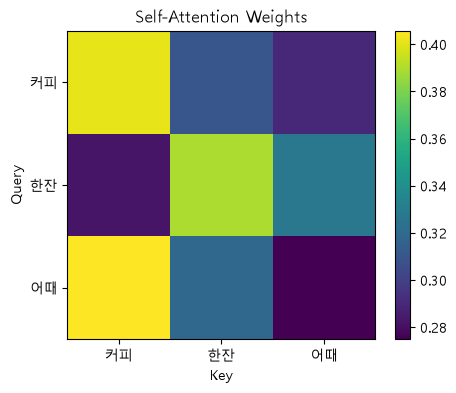

In [16]:
# 밝거나 큰 값을 가진 위치일수록 해당 query가 해당 key를 더 많이 참고한다는 뜻
import matplotlib.pyplot as plt

weights_np = weights.detach().numpy()

plt.rcParams["font.family"] = "Malgun Gothic"
plt.figure(figsize=(5, 4))
plt.imshow(weights_np)
plt.xticks(range(len(token)), token)
plt.yticks(range(len(token)), token)
plt.xlabel("Key")
plt.ylabel("Query")
plt.title("Self-Attention Weights")
plt.colorbar()
plt.show()

# **5. Transformer**

트랜스포머(Transformer)는 ***2017년 구글 논문(Attention is all you need)에서 발표된 자연어 처리(NLP)와 다양한 시퀀스 학습 문제에서 뛰어난 성능을 보이는 신경망 아키텍처로, 어텐션 메커니즘을 활용하여 병렬 연산이 가능하고 장기 의존성을 효과적으로 처리할 수 있다.** 기존의 순환신경망(RNN)과 달리 순차적인 계산 없이 전체 입력 문장을 한 번에 처리하며, 특히 **"셀프 어텐션(Self-Attention)"을 사용하여 문장 내 단어 간 관계를 동적으로 학습**한다. 대표적인 트랜스포머 기반 모델로는 BERT, GPT, T5 등이 있으며, 머신 번역, 텍스트 생성, 문서 요약 등 다양한 AI 분야에서 널리 활용되고 있다. [논문](https://arxiv.org/pdf/1706.03762)

![트랜스포머](./images/트랜스포머.png)

### Encoder
- 문장 > Tokenization > Token ID > Embedding > 위치 정보 추가(Positional Encoding) > Multi-Head Self-Attention > Residual + LayerNorm

##### **1. Token ID 만들기**
Tokenizer가 문자열을 토큰으로 나누고 정수 ID로 바꾼다.

In [17]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(2026)
torch.set_printoptions(precision=3, sci_mode=False)

In [18]:
vocab = {"<PAD>":0, "커피":1, "한잔":2, "어때":3}
tokens = ["커피", "한잔", "어때"]
token_ids = torch.tensor([[1, 2, 3]])

print(tokens)
print(token_ids)
print("shape:", token_ids.shape)

['커피', '한잔', '어때']
tensor([[1, 2, 3]])
shape: torch.Size([1, 3])


##### **2. Token ID > Embedding**
정수 ID를 mm.Embedding에 넣어 학습가능한 실수 벡터로 바꾼다.
- 커피 > 1 > [8개의 실수]
- 한잔 > 1 > [8개의 실수]
- 어때 > 1 > [8개의 실수]

In [19]:
vocab_size = len(vocab)
d_model = 8

embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
X = embedding(token_ids)

print(X)
print("shape:", X.shape)  # (batch, sequence_length, d_model)

tensor([[[-0.545,  0.219, -1.496,  0.343, -0.192, -0.903,  0.998,  0.036],
         [ 0.244,  0.073,  0.900, -0.805, -0.531,  1.579,  1.451, -1.079],
         [-2.191,  1.543, -0.777,  2.194,  0.926,  0.685, -0.603,  0.600]]],
       grad_fn=<EmbeddingBackward0>)
shape: torch.Size([1, 3, 8])


##### **3. Positional Encoding**
Self-Attention은 토큰 사이의 관계를 계산하지만, recurrent 구조처럼 입력 순서를 따라 한칸씩 처리하지 않는다. 모델에 각 토큰의 위치 정보를 제공해야 할 필요가 있다. 따라서, Transformer 논문은 sin/cos 기반 positional encoding을 사용했다.
- Transformer 입력 = Token Embedding + Positional Embedding
    - Transformer가 합쳐진 숫자 하나하나를 보고 단어 값 또는 위치 값을 구분하는 것은 아니다.
    - 두 정보가 같은 d_model 차원의 벡터에 의도적으로 섞어서 하나의 입력 표현으로 만드는 것이다.

각 위치에 서로 다른 sin/cos 패턴을 만들어 임베딩에 더하면 여러 주기의 신호를 함꼐 사용하므로 위치마다 다른 패턴을 얻을 수 있다.
```
Token Embedding E = [단어를 표현하는 숫자들]
Position P = [현재 위치를 표현하는 sin/cos 패턴]
입력 X = E + P

커피 = [0.20, -0.40, 0.70, ... ]
0번 위치의 Position = [0.00, 1.00, 0.00, ...]
최종 입력 [0.20, 0.60, 0.70, ...]
``` 
> 예를 들어, "나는 너를 좋아해"와 "너는 나를 좋아해"는 비슷한 단어가 등장하지만 위치와 문법적 역할이 달라 의미도 달라진다.

In [20]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100):
        super().__init__()
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1) # [max_len, 1]

        div_term = torch.exp( # [d_model/2]
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )
        
        pe = torch.zeros(max_len, d_model) # [max_len, d_model]
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        # 학습 파라미터가 아닌 고정 텐서이므로 buffer로 등록
        # pe는 공식으로 미리 계산해 놓은 고정값
        self.register_buffer("pe", pe.unsqueeze(0)) # [1, max_len, d_model]

    def forward(self, x):
        seq_len = x.size(1) # x: [batch, seq_len, d_model]
        return x + self.pe[:, :seq_len] # [batch, seq_len, d_model]

pos_encoding = PositionalEncoding(d_model)
X_pos = pos_encoding(X)

print("Embedding:", X.shape)
print("Position 추가:", X_pos.shape)
print(X_pos)

Embedding: torch.Size([1, 3, 8])
Position 추가: torch.Size([1, 3, 8])
tensor([[[-0.545,  1.219, -1.496,  1.343, -0.192,  0.097,  0.998,  1.036],
         [ 1.085,  0.614,  1.000,  0.190, -0.521,  2.579,  1.452, -0.079],
         [-1.282,  1.127, -0.578,  3.174,  0.946,  1.685, -0.601,  1.600]]],
       grad_fn=<AddBackward0>)


c:\MCP\agentlog\mcp04_multimodal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


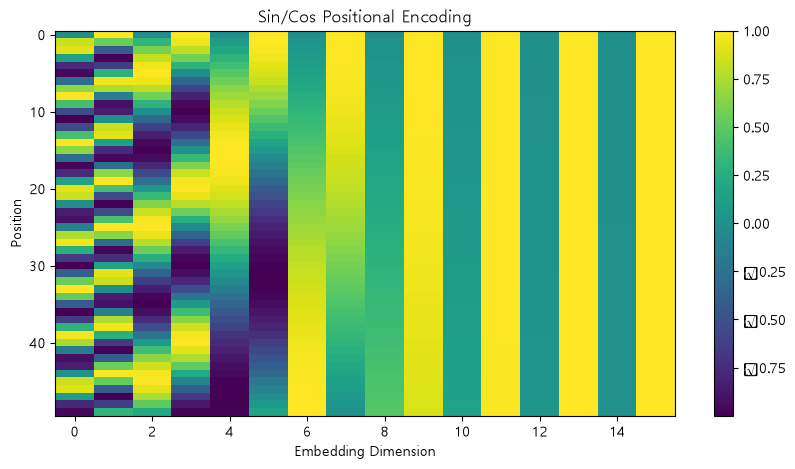

In [21]:
import matplotlib.pyplot as plt

pe_demo = PositionalEncoding(d_model=16, max_len=50)
values = pe_demo.pe[0].detach().numpy()

plt.figure(figsize=(10, 5))
plt.imshow(values, aspect="auto")
plt.xlabel("Embedding Dimension")
plt.ylabel("Position")
plt.title("Sin/Cos Positional Encoding")
plt.colorbar()
plt.show()

##### **4. Multi-Head Self-Attention**

In [22]:
num_heads = 2

mha = nn.MultiheadAttention(
    embed_dim=d_model,
    num_heads=num_heads,
    batch_first=True
)

attn_out, attn_weights = mha(
    query=X_pos, key=X_pos, value=X_pos,
    need_weights=True,
    average_attn_weights=False
)

print("입력:", X_pos.shape)
print("출력:", attn_out.shape)
print("Head별 Weight:", attn_weights.shape)

입력: torch.Size([1, 3, 8])
출력: torch.Size([1, 3, 8])
Head별 Weight: torch.Size([1, 2, 3, 3])


##### **5. Residual Connection**
Residual/Skip connection은 attention 결과에 원래 입력을 다시 더하는 것이다.
- y = x + F(x)

원래 정보(x)를 유지한 채 새로 계산한 정보(F(x))를 보태는 형태이다. 기존 내용 위에 수정/보완분을 더해서 전달할 수 있다. 따라서, 역전파에서 학습 신호가 복잡한 attention/FFN 경로만 통하지 않고 직접적으로 이전 층까지 갈 수 있는 길이 더 생기는 것이다.

In [23]:
x_original = X_pos[0, 0]
attention_change = attn_out[0, 0]
x_after_residual = x_original + attention_change

print("원래 입력 x        :", x_original)
print("Attention 결과 F(x):", attention_change)
print("Residual x + F(x)  :", x_after_residual)
print("x shape    :", x_original.shape) # shape가 같아야 원소별 덧셈이 가능
print("F(x) shape :", attention_change.shape)

원래 입력 x        : tensor([-0.545,  1.219, -1.496,  1.343, -0.192,  0.097,  0.998,  1.036],
       grad_fn=<SelectBackward0>)
Attention 결과 F(x): tensor([-0.497, -0.147,  0.130,  0.086, -0.147, -0.007, -0.149,  0.629],
       grad_fn=<SelectBackward0>)
Residual x + F(x)  : tensor([-1.042,  1.072, -1.365,  1.429, -0.339,  0.090,  0.849,  1.665],
       grad_fn=<AddBackward0>)
x shape    : torch.Size([8])
F(x) shape : torch.Size([8])


In [24]:
residual = X_pos + attn_out

print(residual.shape)

torch.Size([1, 3, 8])


##### **6. Layer Normalization**
한 개의 입력 샘플 내부의 모든 뉴런 값에 대해 평균과 분산을 계산하여 정규화하는 방식이다. 즉, 각 배치의 크기와 무관하게 특징(feature) 차원별로 정규화하므로, 시퀀스 길이가 달라져도 안정적으로 작동한다. Residual에서 원래 정보 + 새 정보를 합친 뒤 값의 분포가 지나치게 흔들리지 않도록 정돈한다.

In [25]:
norm1 = nn.LayerNorm(d_model)
x1 = norm1(residual)

print("전:", residual[0,0])
print("후:", x1[0,0])
print("평균:", x1[0,0].mean())
print("분산:", x1[0,0].var(unbiased=False))

전: tensor([-1.042,  1.072, -1.365,  1.429, -0.339,  0.090,  0.849,  1.665],
       grad_fn=<SelectBackward0>)
후: tensor([-1.256,  0.730, -1.560,  1.066, -0.595, -0.193,  0.520,  1.288],
       grad_fn=<SelectBackward0>)
평균: tensor(0.000, grad_fn=<MeanBackward0>)
분산: tensor(1.000, grad_fn=<VarBackward0>)


##### **7. Feed Forward Network(FFN)**
Attention만 하면 다른 토큰에게서 어떤 정보를 가져올 지는 계산할 수 있지만, 가져온 정보를 각 토큰 안에서 충분히 비선형적으로 가공하는 단계가 필요하다. 
- Attention: 토큰들이 서로 정보를 주고 받음
- FFN: 모든 위치에 같은 작은 신경망을 독립적으로 적용하여, 정보를 받은 각 토큰 벡터를 개별적으로 비선형 변환
> 논문에서는 512 > 2048 > 512로 차원을 변환시켰다.

In [26]:
ffn = nn.Sequential(
    nn.Linear(d_model, 32),
    nn.ReLU(),
    nn.Linear(32, d_model)
)

ffn_out = ffn(x1)
print("입력:", x1.shape)
print("출력:", ffn_out.shape)

입력: torch.Size([1, 3, 8])
출력: torch.Size([1, 3, 8])


##### 두번째 residual도 같은 원리
- 첫번째 residual: Attentio이 만든 변화량을 원래 값에 더함
- 두번쩨 residual: FFN이 만든 변화량을 FFN 입력에 더함
> 한 encoder block 안에 보통 attention용 residual 1개, FFN용 residual 1개로 구성된다.

In [27]:
norm2 = nn.LayerNorm(d_model)
encoder_output = norm2(x1 + ffn_out)
print(encoder_output)
print(encoder_output.shape)

tensor([[[-1.192,  0.787, -1.456,  1.027, -1.070,  0.099,  0.867,  0.937],
         [-0.302, -0.276, -0.002, -0.457, -1.390,  2.246,  0.652, -0.471],
         [-1.626,  0.182, -0.915,  1.775, -0.432,  0.766, -0.389,  0.638]]],
       grad_fn=<NativeLayerNormBackward0>)
torch.Size([1, 3, 8])


##### **8. Padding Mask**
배치 안의 문장 길이를 맞추기 위해 \<PAD\>를 넣어준다.
```
커피 한잔 어때
커피 어때 <PAD
```
\<PAD\>는 의미가 없다. 따라서, attention에서 참고하지 않아야 한다. \<PAD\>를 가리지 않으면 attention이 가중치를 줄 수 있어 의미없는 정보를 참고하게 된다.


In [28]:
padded_ids = torch.tensor([
    [1, 2, 3],
    [1, 3, 0]
])

padding_mask = padded_ids.eq(0)

print(padded_ids)
print(padding_mask)
# False = 실제 토큰
# True  = PAD

tensor([[1, 2, 3],
        [1, 3, 0]])
tensor([[False, False, False],
        [False, False,  True]])


In [29]:
padded_x = pos_encoding(embedding(padded_ids))

# key_padding_mask: key 위치는 참고 대상에서 제외
masked_out, masked_weights = mha(
    padded_x, padded_x, padded_x,
    key_padding_mask=padding_mask,
    need_weights=True
)

print(masked_weights)
print("\n두 번째 문장")
print(masked_weights[1])

tensor([[[0.277, 0.322, 0.401],
         [0.377, 0.205, 0.418],
         [0.286, 0.299, 0.414]],

        [[0.392, 0.608, 0.000],
         [0.372, 0.628, 0.000],
         [0.414, 0.586, 0.000]]], grad_fn=<MeanBackward1>)

두 번째 문장
tensor([[0.392, 0.608, 0.000],
        [0.372, 0.628, 0.000],
        [0.414, 0.586, 0.000]], grad_fn=<SelectBackward0>)


### Encoder Block 직접 만들기

In [30]:
class SimpleTransformerEncoderBlock(nn.Module):
    def __init__(self, d_model=8, num_heads=2, d_ff=32, dropout=0.1):
        super().__init__()

        self.self_attention = nn.MultiheadAttention(
            d_model, num_heads,
            dropout=dropout,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )

        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, padding_mask=None):
        attn_out, weights = self.self_attention(
            x, x, x,
            key_padding_mask=padding_mask,
            need_weights=True
        )

        x = self.norm1(x + self.dropout1(attn_out))

        ffn_out = self.ffn(x)
        x = self.norm2(x + self.dropout2(ffn_out))

        return x, weights

block = SimpleTransformerEncoderBlock()
out, weights = block(X_pos)

print("입력:", X_pos.shape)
print("출력:", out.shape)
print("Weight:", weights.shape)

입력: torch.Size([1, 3, 8])
출력: torch.Size([1, 3, 8])
Weight: torch.Size([1, 3, 3])


### Decoder
- Encoder: 입력 토큰들의 관계를 Self-Attention으로 처리
- Decoder: 출력 생성
    - Masked Self-Attention: Causal mask를 사용하여 미래 출력 토큰을 보지 않음
    - Cross-Attention: Encoder의 출력 정보를 참고
```
입력 > Encoder > 출력 > Masked Self-Attention > Cross-Attention > FFN >출력
```

##### **1. Causal Mask**
- Padding Mask: 의미 없는 PAD를 차단
- Causal Mask: 미래 토큰을 미리 보지 못하게 차단
    - 다음 토큰 생성에서는 현재 위치보다 뒤에 있는 정답을 미리 보면 안된다.
```
        나는    커피를   마신다
나는      O       X        X
커피를    O       O        X
마신다    O       O        O
```
> GPT 계열의 autoregressive 생성 원리를 이해할 때 매우 중요하다.

- 학습 때 정답 문장을 알고 있는데도 Mask가 필요한 이유?
    - 다음 토큰 예측 학습에서는 정답 시퀀스를 한꺼번에 넣어 병렬 계산할 수 있는데, Mask가 없다면 앞 위치가 뒤쪽의 정답 토큰을 미리 볼 수 있어 데이터 누수가 생길 수 있다. 따라서, 병렬 계산은 하되, 각 위치가 과거/현재까지만 보도록 제한해야 한다.

In [31]:
seq_len = 4

# triu(): 상삼각 부분만 남기는 함수
causal_mask = torch.triu(
    torch.ones(seq_len, seq_len, dtype=torch.bool),
    diagonal=1  # 대각선(자기 자신)은 제외하고, 그 위쪽(미래 토큰)만 True로 남김
)

# False = 볼 수 있음
# True = 미래이므로 차단
print(causal_mask)

tensor([[False,  True,  True,  True],
        [False, False,  True,  True],
        [False, False, False,  True],
        [False, False, False, False]])


##### **2. Cross-Attention**
Decoder가 현재 출력을 만들기 위해 입력 문장의 어디를 참고해야 하는 가를 계산하는 과정이다.
```
Q: Decoder의 현재 표현
K: Encoder 출력
V: Encoder 출력
```

In [32]:
cross_attention = nn.MultiheadAttention(
    embed_dim=8,
    num_heads=2,
    batch_first=True
)

encoder_memory = torch.randn(1, 5, 8)
decoder_state = torch.randn(1, 3, 8)

cross_out, cross_weights = cross_attention(
    query=decoder_state,
    key=encoder_memory,
    value=encoder_memory
)

print("Q(Decoder):", decoder_state.shape)
print("K/V(Encoder):", encoder_memory.shape)
print("출력:", cross_out.shape)
print("Weight:", cross_weights.shape)

Q(Decoder): torch.Size([1, 3, 8])
K/V(Encoder): torch.Size([1, 5, 8])
출력: torch.Size([1, 3, 8])
Weight: torch.Size([1, 3, 5])


# **6. BERT, GPT, T5를 구조 관점에서 보기**

- BERT 계열: Encoder 중심, 양방향 문맥 표현을 이용하는 이해 작업에 널리 사용되었음
- GPT 계열: Decoder 계열의 Causal Self-Attention을 사용하는 autoregressive 구조, 앞의 토큰으로 다음 토큰을 예측함
- T5 계열: Encoder-Decoder transformer
> Transformer라고해서 항상 encoder와 decoder 전체를 모두 사용하는 것은 아니다.